<a href="https://colab.research.google.com/github/jfypes/telecom-analysis/blob/main/Proyecto_6_An%C3%A1lisis_de_una_empresa_de_telecomunicaciones.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
pd.DataFrame({
    'cantidad_nulos': users.isna().sum(),
    'porcentaje_nulos': users.isna().mean()*100
}).sort_values(by='cantidad_nulos', ascending= False)

,cantidad_nulos,porcentaje_nulos
churn_date,3534,88.350
city,469,11.725
user_id,0,0.000
first_name,0,0.000
last_name,0,0.000
age,0,0.000
reg_date,0,0.000
plan,0,0.000


In [ ]:
# cantidad de nulos para usage
pd.DataFrame({
    'cantidad_nulos': usage.isna().sum(),
    'porcentaje_nulos': usage.isna().mean()*100
}).sort_values(by='cantidad_nulos', ascending= False)

,cantidad_nulos,porcentaje_nulos
duration,22076,55.190
length,17896,44.740
date,50,0.125
id,0,0.000
user_id,0,0.000
type,0,0.000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
  - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
  - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
  - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
    - Las columnas que tienen valores nulos son:
      
      * En users:
        * '**churn_date**' con 88.35%
        * '**city**' con 11.73%
      * En usage:
        * '**duration**' con 55.19%
        * '**length**' con 44.74%
        * '**date**' con 0.125%
- Indica qué harías: ¿imputar, eliminar, ignorar?
    * En users:
        * '**churn_date**' **ignoraría** los valores nulos ya que hacen referencia a clientes aún activos.
        * '**city**' **ignoraría** los valores nulos y si existen sentinels los **imputaría** reemplazando por `NA`.
    * En usage:
        * '**duration**' **ignoraría** los valores nulos porque significan que se envió un mensaje.
        * '**length**' **ignoraría** los valores nulos porque significan que se hizo un llamada.
        * '**date**' **ignoraría**, dejándolas como nulas.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
# explorar columnas numéricas de users

columnas_numericas_users = users.select_dtypes(include = "number").columns.tolist()
print(users[columnas_numericas_users].describe())

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


- La columna `user_id` si es un número y por lo tanto arroja un resumen estadístico pero no es relevante para el análisis ya que solo es un identificador, no una medida con significado estadístico.
- La columna `age` si es una medida con significado estadístico y aporta información para el análisis. Algo a tener en cuenta, es la aparición de un valor mínimo (-999).

In [ ]:
print(users["age"].unique())
print()
sentinel=users[users["age"]==-999]
print("Existes",len(sentinel), "clientes con una edad de -999. Esto representa un ",(len(sentinel)/users["age"].count())*100,"% del total de los datos")

[  38   53   57   69   63   61   39   70   76   47   67   60 -999   78
   77   25   51   74   64   26   68   37   42   36   22   28   32   40
   44   49   43   79   59   46   56   58   50   54   33   24   29   45
   66   30   35   65   18   55   19   23   41   27   34   72   75   31
   71   52   20   73   21   62   48]

Existes 55 clientes con una edad de -999. Esto representa un  1.375 % del total de los datos


In [ ]:
# explorar columnas numéricas de usage

columnas_numericas_usage = usage.select_dtypes(include = "number").columns.tolist()
print(usage[columnas_numericas_usage].describe())

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id` no son columnas que tengas una medida con significado estadístico para el análisis
- Las columnas `duration`y `length` son las que tienen valor real para el análisis. Es importante tener presente que los máximos de `duration` (120) y `length` (1490) se encuentran muy por encima del percentil 75, por lo que conviene investigarlos como posibles outliers.

In [ ]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
print(users[columnas_user].describe())

          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595


- La columna `city` tiene 7 valores únicos y si presenta valores nulos. Es importante revisar si cada uno de los 7 valores únicos presentes en esta columna corresponder a una ciudad o si existen sentinels dentro de ella.
- La columna `plan` tiene 2 valores únicos, `Basico` y `Premium`. No presenta valores nulos y el plan Básico es el más contratado por los usuarios.

In [ ]:
sorted(users["city"].dropna().unique())

['?', 'Bogotá', 'CDMX', 'Cali', 'GDL', 'MTY', 'Medellín']

In [ ]:
sentinel_city=users[users["city"]=='?']
print("Existen",len(sentinel_city), 'sentinels dentro de la columna city que deben ser analizados')

Existen 96 sentinels dentro de la columna city que deben ser analizados


- Además de los valores nulos presentes en la columna `city`, existe un sentinel `?`que debe ser revisado para tomar una decisión.

In [ ]:
# explorar columna categórica de usage
usage['type'].describe()

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

- La columna `type` tiene 2 valores únicos, `text` y `call`. Y no tiene valores nulos.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
  *En la columna `age` y en la columna `city`existen sentinels
- ¿Qué acción tomarías?
  * En la columna `age`reemplazaría los sentinels por la mediana y en la columna `city` reemplazaría `?`con `NaN`.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors= 'coerce')

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors= 'coerce')

In [ ]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.unique()

array([2022.,   nan, 2023., 2024.])

En `reg_date`, cualquier dato que tenga el año `2026` como fecha de registro debe ser tratado como `NaT` ya que solo se va a trabajar hasta el año `2024`

In [ ]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.unique()

array([2024.,   nan])

En `date` están presentes los datos del año 2024 lo cual coincide con lo que se quiere analizar para ConnectaTel.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
  * Si, en la columna `reg_date` aparece en año `2026` y el análisis se debe basar en los datos registrados hasta el año `2024`
- ¿Qué harías con ellas?
  * Las marcaría como `NaT`.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
users['age']=users['age'].replace(-999, np.nan)
age_mediana = users['age'].median()
users['age'] = users['age'].fillna(age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:

# Reemplazar ? por NA en city
users['city']=users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].describe()


count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [ ]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year==2026, 'reg_date']= pd.NaT
# Verificar cambios
users['reg_date'].dt.year.unique()

array([2022.,   nan, 2023., 2024.])

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda x: x.isna().sum())

type
call        0
text    22076
Name: duration, dtype: int64

In [ ]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda x: x.isna().sum())

type
call    17896
text        0
Name: length, dtype: int64

Esto confirma que los dos patrones son `MAR`. Los nulos de `duration` dependen completamente de `text`ya que los mensajes no tienen `duración`, tienen `longitud`. Lo mismo ocurre con `length` y `call`(las llamadas no tienen `lomgitud`, tienen `duración`). Por este motivo se dejan como nulos y no se imputan.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({'is_text':'sum', 'is_call': 'sum', 'duration': 'sum'}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg=usage_agg.rename(columns={'is_text': 'cant_mensajes', 'is_call': 'cant_llamadas', 'duration': 'cant_minutos_llamada'})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how= 'left')
columnas_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[columnas_uso] = user_profile[columnas_uso].fillna(0)
user_profile.head(3)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
columnas_numericas_user_profile=['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
print(user_profile[columnas_numericas_user_profile].describe())
print()
mediana_user_profile=user_profile[columnas_numericas_user_profile].median().to_frame().T.rename(index={0: 'Mediana'})
print(mediana_user_profile)

               age  cant_mensajes  cant_llamadas  cant_minutos_llamada
count  4000.000000    4000.000000    4000.000000           4000.000000
mean     48.136000       5.523000       4.477000             23.311225
std      17.689919       2.359738       2.145139             18.169564
min      18.000000       0.000000       0.000000              0.000000
25%      33.000000       4.000000       3.000000             11.107500
50%      48.000000       5.000000       4.000000             19.780000
75%      63.000000       7.000000       6.000000             31.412500
max      79.000000      17.000000      15.000000            155.690000

          age  cant_mensajes  cant_llamadas  cant_minutos_llamada
Mediana  48.0            5.0            4.0                 19.78


In [ ]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)*100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

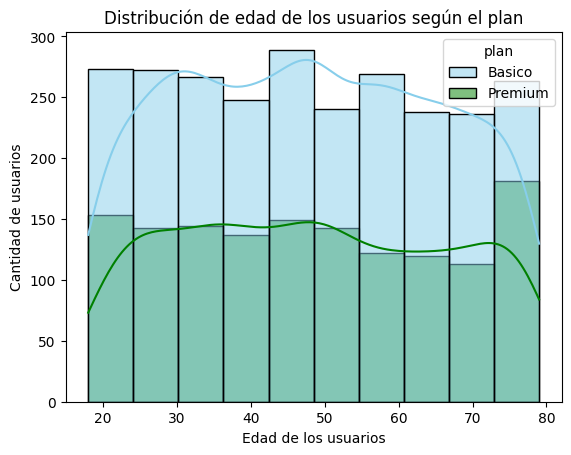

In [ ]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x= 'age', bins= 10, palette=['skyblue', 'green'], hue= 'plan', kde=True)
plt.xlabel('Edad de los usuarios')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de edad de los usuarios según el plan')
plt.show()

💡Insights: El plan Básico es elegido por más usuarios que el plan Premium en todos los rangos de edad analizados, de forma consistente con la proporción general de 65%-35%
- Distribución es simétrica para ambos planes.

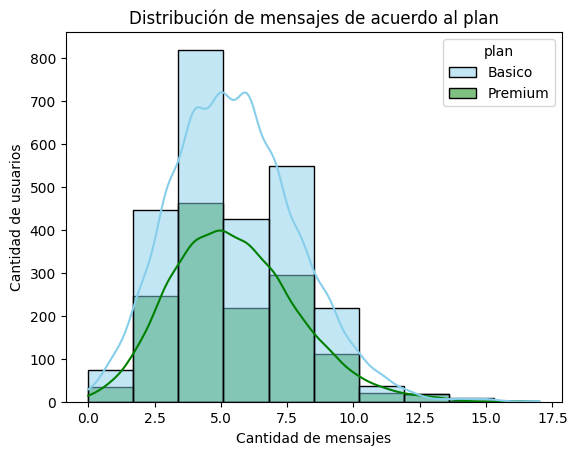

In [ ]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x= 'cant_mensajes', bins= 10, palette=['skyblue', 'green'], hue= 'plan', kde=True)
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de mensajes de acuerdo al plan')
plt.show()

💡Insights: La mayoría de los usuarios envía pocos mensajes tanto el el plan Básico como en el Premuim.
- Distribución sesgada a la derecha en los dos planes.

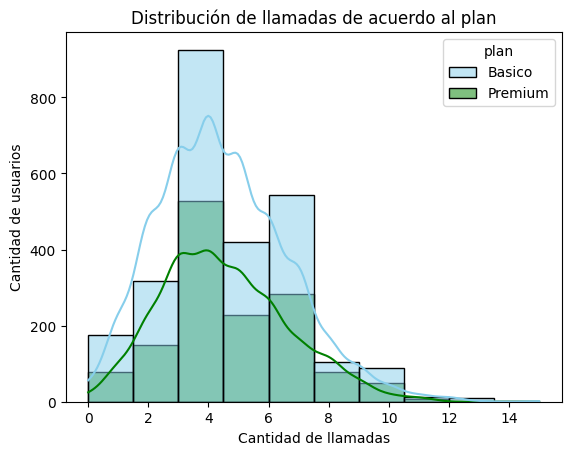

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x= 'cant_llamadas', bins= 10, palette=['skyblue', 'green'], hue= 'plan', kde=True)
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de llamadas de acuerdo al plan')
plt.show()

💡Insights: En los dos tipos de planes se observa que la mayoría de los usuarios realiza pocas llamadas.
- Distribución sesgada a la derecha en ambos planes.

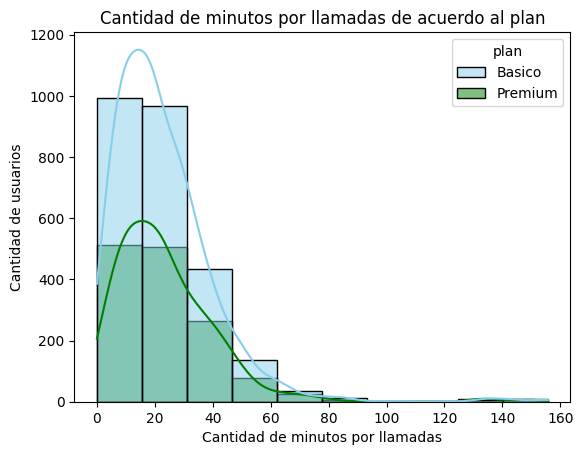

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x= 'cant_minutos_llamada', bins= 10, palette=['skyblue', 'green'], hue= 'plan', kde=True)
plt.xlabel('Cantidad de minutos por llamadas')
plt.ylabel('Cantidad de usuarios')
plt.title('Cantidad de minutos por llamadas de acuerdo al plan')
plt.show()

💡
Insights: Como era de esperarse, la mayoría de las llamadas duran pocos minutos.
- Distribuión sesgada a la derecha para los dos planes.


### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

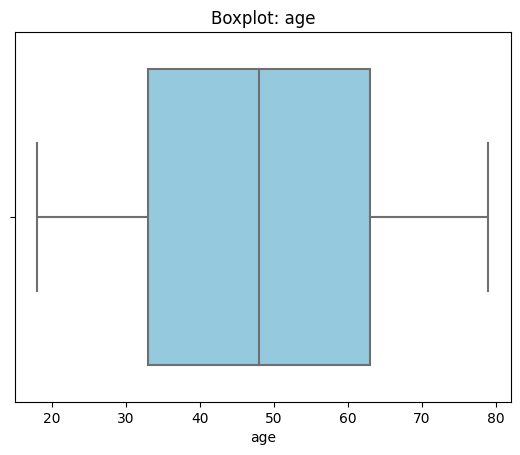

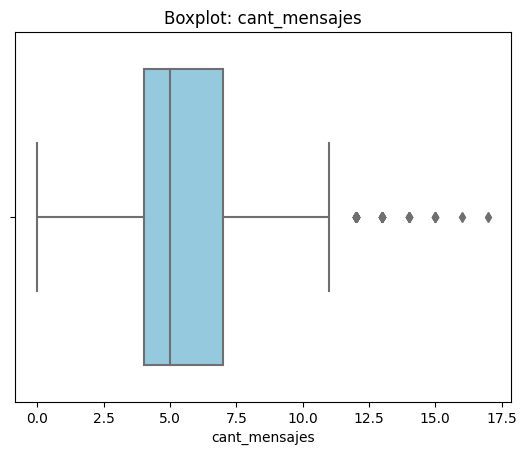

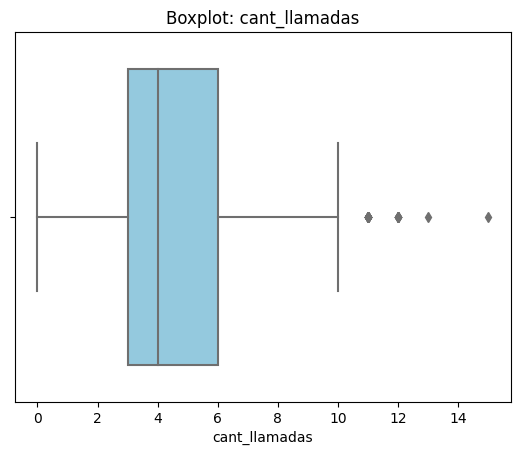

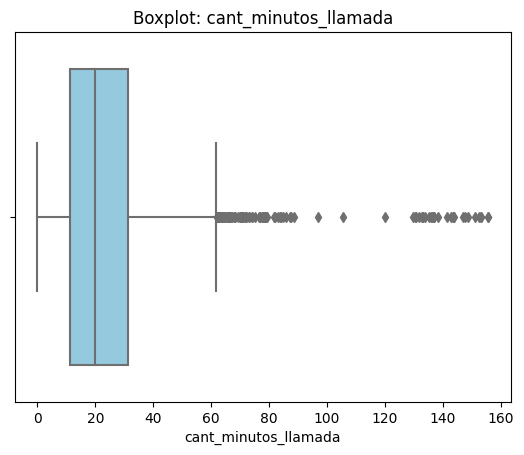

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x= col, color= "skyblue")
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights:
- Age: no presenta outliers
- cant_mensajes: presenta outliers del lado derecho del gráfico hasta 17 mensajes.
- cant_llamadas: Los outliers presentes se observan en la parte derecha del gráfico llegando hasta 15 llamadas.
- cant_minutos_llamada: En el lado derecho del gráfico se observa la presencia de outliers hasta los 155 minutos.

In [ ]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
limites={}
for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3-Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    limites[col]=(lower, upper)
print(limites)

{'cant_mensajes': (-0.5, 11.5), 'cant_llamadas': (-1.5, 10.5), 'cant_minutos_llamada': (-19.35, 61.870000000000005)}


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


In [ ]:
for col, (lower, upper) in limites.items():
    fuera = (user_profile[col] > upper).sum()
    print(f"{col}: {fuera} usuarios son outliers ({fuera / user_profile[col].count() * 100:.2f}%)")

cant_mensajes: 46 usuarios son outliers (1.15%)
cant_llamadas: 30 usuarios son outliers (0.75%)
cant_minutos_llamada: 109 usuarios son outliers (2.73%)



💡 **Insights:**

Los tres outliers están solo en el extremo superior (los límites inferiores son negativos y el mínimo observado es 0). Se **conservan** en los tres casos, porque son valores plausibles y representan variabilidad real del comportamiento de los usuarios, no errores de datos.

- **`cant_mensajes`:** límite superior de 11.5 y máximo de 17. Hay 46 usuarios por encima del límite (1.2% de los 3,999 usuarios con registro de uso).
- **`cant_llamadas`:** límite superior de 10.5 y máximo de 15. Hay 30 usuarios por encima del límite (0.8%).
- **`cant_minutos_llamada`:** límite superior de 61.86 minutos y máximo de 155.69, unas 2.5 veces el límite. Hay 109 usuarios por encima (2.7%), el patrón más extremo.

En los tres casos representan menos del 3% de los usuarios, por lo que no distorsionan los promedios de forma relevante, y eliminarlos haría perder justo a los clientes de consumo más intensivo.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:


# Crear columna grupo_uso
def clasificacion(fila):
    if fila['cant_llamadas'] <5 and fila['cant_mensajes'] <5:
        return 'Bajo uso'
    elif fila['cant_llamadas'] < 10 and fila['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'
user_profile['grupo_uso']=user_profile.apply(clasificacion, axis= 1)
print(user_profile['grupo_uso'].value_counts())
print(user_profile['grupo_uso'].value_counts(normalize=True).mul(100).round(2))

Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64
Uso medio    73.58
Bajo uso     19.48
Alto uso      6.95
Name: grupo_uso, dtype: float64


In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
def clasificacion_edad(edad):
    if edad < 30 :
        return 'Joven'
    elif edad < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'
user_profile['grupo_edad']=user_profile['age'].apply(clasificacion_edad)

In [ ]:
# verificar cambios
print(user_profile['grupo_edad'].value_counts(normalize=True)*100)
user_profile.head()

Adulto          50.45
Adulto Mayor    30.55
Joven           19.00
Name: grupo_edad, dtype: float64


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


In [ ]:
user_profile.groupby('grupo_uso')[['cant_llamadas', 'cant_mensajes', 'cant_minutos_llamada']].mean()

,cant_llamadas,cant_mensajes,cant_minutos_llamada
grupo_uso,,,
Alto uso,5.946043,9.561151,30.149784
Bajo uso,2.804878,3.128370,14.900513
Uso medio,4.780836,5.775399,24.891526


In [ ]:
user_profile['churned'] = user_profile['churn_date'].notna().astype(int)
(user_profile.groupby('grupo_uso')['churned'].mean() * 100).round(2)

grupo_uso
Alto uso     14.03
Bajo uso     11.42
Uso medio    11.48
Name: churned, dtype: float64

In [ ]:
user_profile.groupby('grupo_edad')[['cant_llamadas', 'cant_mensajes', 'cant_minutos_llamada']].mean()

,cant_llamadas,cant_mensajes,cant_minutos_llamada
grupo_edad,,,
Adulto,4.480674,5.545590,22.985263
Adulto Mayor,4.502455,5.486088,23.575974
Joven,4.426316,5.522368,23.751053


In [ ]:
(user_profile.groupby('grupo_edad')['churned'].mean() * 100).round(2)

grupo_edad
Adulto          12.49
Adulto Mayor    10.97
Joven           10.53
Name: churned, dtype: float64

### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

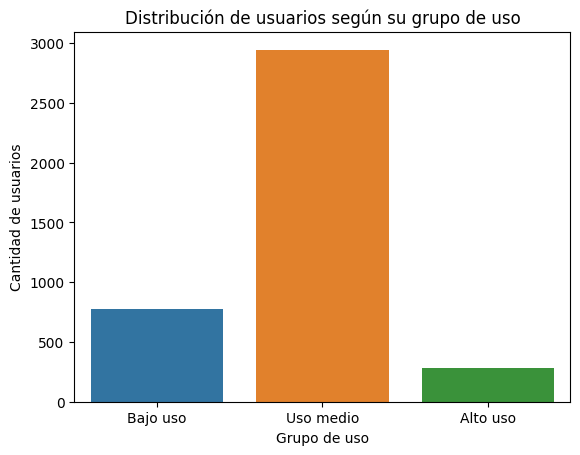

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x= 'grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'])
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de usuarios según su grupo de uso')
plt.show()

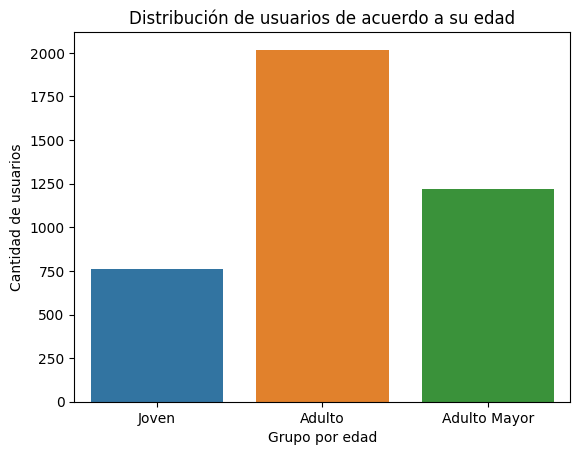

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x= 'grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'])
plt.xlabel('Grupo por edad')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de usuarios de acuerdo a su edad')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

Los datos presentaban tres tipos de problemas: valores nulos, valores centinela (valores que no deberían existir) y fechas fuera de rango. Un hallazgo clave es que **no todos los nulos son iguales**: algunos son *estructurales* (el dato no aplica al registro) y otros son *faltantes reales* (el dato debería existir y no está). Esto determina el tratamiento de cada columna.

## `users_latam.csv`

- **`churn_date` (88.35% de nulos, 3,534 filas, estructural):** los nulos corresponden a clientes que siguen activos en alguno de los dos planes de ConnectaTel, por lo que no son un error y se conservan. Eliminar la columna o imputar fechas habría distorsionado el análisis de permanencia. Como indicador de negocio, el churn observado es de ~11.65%.
- **`age` (centinela `-999`, 55 filas, 1.4%):** es un valor imposible que distorsionaba el resumen estadístico (promedio de 33.7 con mínimo de -999). Se reemplazó por la mediana (48 años).
- **`city` (469 nulos, 11.73%, y centinela `"?"`, 96 filas, 2.4%):** el `"?"` se convirtió en nulo, por lo que la columna quedó con 565 nulos (14.1%). No se imputó ninguna etiqueta: los nulos se conservan como tales para no inventar información.
- **`reg_date` (40 filas, 1.0%, fechas fuera de rango):** tenían año 2026, pero los datos llegan hasta 2024. Se marcaron como nulas (`NaT`).

## `usage.csv`

- **`date` (0.125% de nulos, 50 filas, faltante real):** al ser un porcentaje mínimo, se pueden dejar esas filas como nulas (`NaT`).
- **`duration` (55.19% de nulos) y `length` (44.74% de nulos), estructurales:** se verificó que dependen de `type`: `duration` solo se registra en las llamadas y `length` solo en los mensajes. Ambos porcentajes suman 100%, por lo que son mutuamente excluyentes. Se dejan como nulos.

🔍 **Segmentos por Edad y churn**

El segmento Adulto (30-59 años) reúne al 50.45% de los clientes, Adulto Mayor (60 años o más) al 30.55% y Joven (menos de 30) al 19.00%.

La actividad promedio es muy similar entre los tres grupos de edad (~4.4-4.5 llamadas, ~5.5 mensajes y ~23-23.8 minutos de llamada), por lo que la edad no parece diferenciar el nivel de uso del servicio. Sin embargo, el segmento Adulto presenta la tasa de churn más alta (12.49%), frente a 10.97% en Adulto Mayor y 10.53% en Joven. Al ser además el segmento más numeroso, es el que más clientes aporta al abandono total.

**Limitaciones:** este análisis es descriptivo. La diferencia en la tasa de churn es moderada (entre 1.5 y 2 puntos porcentuales) y no se evaluó si es estadísticamente significativa. Tampoco se exploraron las causas del mayor abandono en el segmento Adulto, por lo que el resultado se interpreta como una señal a investigar y no como una conclusión definitiva.

**Recomendación:** monitorear la tasa de churn del segmento Adulto, dado su peso en la base de clientes, y como siguiente paso analizar su comportamiento por plan para identificar posibles causas del abandono.

📊 **Segmentos por Nivel de Uso y churn**

El segmento Bajo uso reúne a 779 usuarios (19.48%), Uso medio a 2943 usuarios (73.58%) y Alto uso a 278 usuarios (6.95%).

Los segmentos se diferencian claramente en las tres métricas de consumo: el grupo de Alto uso realiza en promedio ~5.9 llamadas, ~9.6 mensajes y ~30 minutos de llamada, frente a ~2.8, ~3.1 y ~14.9 del grupo de Bajo uso.

En cuanto al churn, el segmento de Alto uso presenta la tasa más alta (13.98%), unos 2.5 puntos porcentuales por encima de Uso medio (11.48%) y Bajo uso (11.44%), que prácticamente no se diferencian entre sí. Es decir, un mayor uso del servicio no se asocia con una mayor permanencia; los clientes más activos son los que más abandonan.

**Limitaciones:** este análisis es descriptivo. No se evaluó si la diferencia de 2.5 puntos es estadísticamente significativa, ni se exploraron las causas (por ejemplo, el plan contratado). Por ello, el resultado se interpreta como una señal a investigar y no como una conclusión definitiva.

**Recomendación:** priorizar acciones de retención en el segmento de Alto uso y, como siguiente paso, analizar su churn por plan para identificar si el plan se ajusta a su nivel de consumo.

### Patrones de uso extremo (outliers)

Con el método IQR se identificaron valores atípicos únicamente en el extremo superior de las tres variables de uso. Los límites inferiores son negativos y el mínimo observado es 0, por lo que no existen outliers por debajo.

- **`cant_mensajes`:** límite superior de 11.5, con un máximo de 17. Hay 46 usuarios por encima del límite (1.15%).
- **`cant_llamadas`:** límite superior de 10.5, con un máximo de 15. Hay 30 usuarios por encima del límite (0.75%).
- **`cant_minutos_llamada`:** límite superior de 61.86 minutos, con un máximo de 155.69, el patrón más extremo. Hay 109 usuarios por encima del límite (2.%).

En las tres variables la media supera a la mediana, lo que indica distribuciones con sesgo a la derecha, esperables en datos de consumo. Los valores máximos son plausibles y no hay valores negativos ni imposibles, por lo que se interpretan como variabilidad real del comportamiento de los usuarios y **no como errores de datos**. Por esta razón se decidió **conservarlos**.

**Implicaciones para el negocio:** estos valores corresponden a usuarios de consumo muy intensivo. Eliminarlos implicaría perder información justo de los clientes que más usan el servicio, el segmento que presentó la mayor tasa de churn (Alto uso, 13.98%).

**Limitaciones:** no se midió el churn de forma específica en los usuarios atípicos, por lo que su relación con el abandono se interpreta como una hipótesis y no como un resultado comprobado.

**Recomendación:** tratar a los usuarios de uso extremo como un grupo de alto valor a vigilar, y como siguiente paso evaluar si su plan actual se ajusta a su nivel de consumo.

💡 **Recomendaciones para la oferta de planes**

**1. Diseñar la oferta por nivel de uso y no por edad.**
La actividad promedio es casi idéntica entre los tres grupos de edad (~4.4-4.5 llamadas, ~5.5 mensajes, ~23-23.8 minutos), mientras que los segmentos de uso sí se separan claramente (Alto uso: ~6 llamadas, ~9.6 mensajes y ~30 minutos; Bajo uso: ~2.8, ~3.1 y ~14.9). Por eso, el nivel de consumo es un criterio más útil que la edad para diferenciar planes.

**2. Evaluar un plan o beneficio para el segmento de Alto uso.**
Es el segmento con mayor churn (13.98% frente a ~11.5% en los otros dos) y concentra los usuarios de consumo extremo (por encima de ~61.9 minutos, 11.5 mensajes o 10.5 llamadas). Una hipótesis a validar es que el plan actual no se ajusta a su nivel de consumo. Un plan con mayor volumen incluido de minutos y mensajes, o con beneficios de fidelización, podría reducir su abandono.

**3. Mantener una oferta simple para Bajo y Medio uso.**
Ambos segmentos tienen un churn prácticamente igual (11.44% y 11.48%), por lo que los datos no justifican crear planes distintos para ellos. Una opción es un plan base común, con incentivos para que los usuarios de Uso medio migren hacia planes de mayor valor.

**4. Reforzar la retención en el segmento Adulto.**
Es el grupo de edad más numeroso (~50% de la base) y el de mayor churn (12.49%). Al no diferenciarse en uso, se sugiere abordarlo con acciones de retención más que con un plan específico por edad.

**Limitaciones:** el análisis es descriptivo. No se evaluó el churn por plan, ni precios o ingresos por segmento, ni si las diferencias de churn son estadísticamente significativas. Las recomendaciones son hipótesis a validar, no conclusiones comprobadas.

**Siguiente paso:** analizar el churn del segmento de Alto uso según su plan actual y validar cualquier plan nuevo con una prueba piloto antes de lanzarlo.



## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: https://github.com/jfypes/telecom-analysis